# Phase 7: split by photo (train / val / test)

| Split | Share of photos | What it is for |
|---|---|---|
| **train** | 70% | what the model studies (learn and tune) |
| **val** | 15% | the practice exam: pick settings and compare models |
| **test** | 15% | the final exam: used **once**, at the very end |

**Why by photo, not by square:** neighbouring squares from one photo look almost the same (same road, light, camera). If one square is in train and its neighbour in test, the model has "seen the answer". That is **data leakage**, and it makes the scores look better than they really are. So all 40 squares of a photo always go to the same split.

### Rules we fix before looking

| Rule | Value | Where it comes from |
|---|---|---|
| Group | `image_id` (one photo = one group) | **Required**, to stop leakage (above) |
| Sizes | 70 / 15 / 15 % of the **photos** | **Assumption** from the guide: a common split; 15% of 6,000 photos is still 900 photos per exam |
| Seed | 42 | `config.SEED`, so the split is the same every time |
| Freeze | the split is saved once and reused | **Required**: re-splitting later would let test photos leak into training decisions |

**Check:** no photo in two splits (tested in code), and each split has roughly the same class shares. If test has almost no D10 (the rarest class), change the seed **now**, before training anything.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config

OUT = config.PROCESSED / "07_split"
OUT.mkdir(exist_ok=True)
SPLITS = ["train", "val", "test"]
NAMES = {"D00": "D00 · Longitudinal crack", "D10": "D10 · Transverse crack", "D20": "D20 · Alligator crack",
         "D40": "D40 · Pothole", "none": "none · No damage"}

patches = pd.read_csv(config.PROCESSED / "06_squares" / "patches.csv")
print(len(patches), "squares from", patches.image_id.nunique(), "photos")

240000 squares from 6000 photos


### 1. Make the split once, then freeze it

Two steps with `GroupShuffleSplit` (it splits **groups**, here photos, not rows):
1. 70% of the photos → train, 30% → the rest.
2. The rest is split in half → 15% val, 15% test.

The result is one row per photo (`split_photos.csv`). If that file already exists, we **load it instead of splitting again**, so the split never changes, even if Phase 6 is re-run with new labels.

In [2]:
frozen = OUT / "split_photos.csv"

if frozen.exists():
    split_photos = pd.read_csv(frozen)
    print("Loaded the frozen split from", frozen.name, "(not re-splitting)")
else:
    photos = patches.drop_duplicates("image_id")[["image_id", "country"]].reset_index(drop=True)

    first = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=config.SEED)
    train_idx, rest_idx = next(first.split(photos, groups=photos.image_id))
    rest = photos.iloc[rest_idx]

    second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=config.SEED)
    val_idx, test_idx = next(second.split(rest, groups=rest.image_id))

    photos["split"] = ""
    photos.loc[train_idx, "split"] = "train"
    photos.loc[rest.index[val_idx], "split"] = "val"
    photos.loc[rest.index[test_idx], "split"] = "test"
    split_photos = photos[["image_id", "split"]]
    split_photos.to_csv(frozen, index=False)
    print("Made a new split and froze it in", frozen.name)

split_photos.split.value_counts().reindex(SPLITS).rename("photos")

Loaded the frozen split from split_photos.csv (not re-splitting)


split
train    4200
val       900
test      900
Name: photos, dtype: int64

### 2. Add the `split` column to every square and save

Each square takes the split of its photo. Saved as `07_split/patches_split.csv` (a new file, so `06_squares/patches.csv` stays the untouched Phase 6 output).

In [3]:
patches = patches.merge(split_photos, on="image_id", how="left", validate="many_to_one")
assert patches.split.notna().all(), "every square must get a split"
patches.to_csv(OUT / "patches_split.csv", index=False)

n = patches.split.value_counts().reindex(SPLITS)
pd.DataFrame({"squares": n, "share": (n / n.sum()).round(3), "photos": n // 40})

,squares,share,photos
split,,,
train,168000,0.70,4200
val,36000,0.15,900
test,36000,0.15,900


### 3. Check: no photo is in two splits (leakage test)

If this cell passes, no square in val or test has a neighbour from the same photo in train.

In [4]:
sets = {s: set(patches.image_id[patches.split == s]) for s in SPLITS}
assert not sets["train"] & sets["val"], "photo in train AND val"
assert not sets["train"] & sets["test"], "photo in train AND test"
assert not sets["val"] & sets["test"], "photo in val AND test"
assert patches.groupby("image_id").split.nunique().max() == 1, "a photo is split across splits"
print("OK: every photo is in exactly one split;", sum(len(v) for v in sets.values()), "photos in total")

OK: every photo is in exactly one split; 6000 photos in total


### 4. Check: does each split have the same class mix?

If one split had, say, half the potholes of the others, the val/test scores would not tell us how the model does on real data. The chart includes `none` on purpose: next to it, the damage classes are tiny. That imbalance is what Phase 8 has to deal with.

In [5]:
LABELS = list(NAMES)
counts = pd.crosstab(patches.label, patches.split).reindex(index=LABELS, columns=SPLITS)
shares = counts / counts.sum()

table = counts.astype(str) + "  (" + (shares * 100).round(2).astype(str) + "%)"
table.index = [NAMES[k] for k in table.index]
table

split,train,val,test
D00 · Longitudinal crack,3231 (1.92%),743 (2.06%),790 (2.19%)
D10 · Transverse crack,1819 (1.08%),323 (0.9%),353 (0.98%)
D20 · Alligator crack,13076 (7.78%),2915 (8.1%),2469 (6.86%)
D40 · Pothole,2130 (1.27%),413 (1.15%),360 (1.0%)
none · No damage,147744 (87.94%),31606 (87.79%),32028 (88.97%)


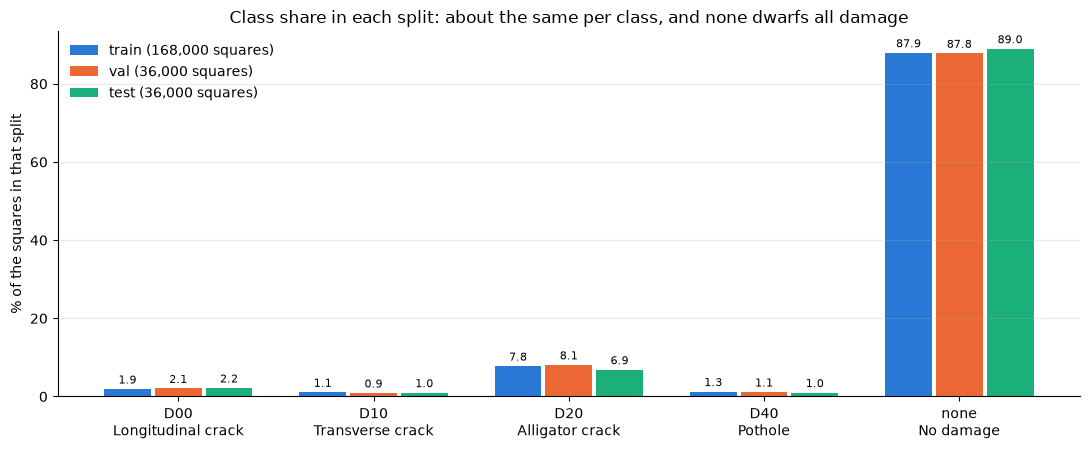

In [6]:
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
x = np.arange(len(LABELS))
w = 0.26

fig, ax = plt.subplots(figsize=(11, 4.6))
for i, s in enumerate(SPLITS):
    bars = ax.bar(x + (i - 1) * w, shares.loc[LABELS, s] * 100, width=w - 0.02, color=SPLIT_COLORS[s],
                  label=f"{s} ({counts[s].sum():,} squares)")
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.set_xticks(x, [NAMES[k].replace(" · ", "\n") for k in LABELS])
ax.set_ylabel("% of the squares in that split")
ax.set_title("Class share in each split: about the same per class, and none dwarfs all damage")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

How far each split is from train, per class (`val / train` and `test / train`; 1.00 means exactly the same share). The rarer the class, the more it can wobble by chance, because fewer photos carry it.

In [7]:
ratio = pd.DataFrame({
    "squares in test": counts["test"],
    "val / train": (shares["val"] / shares["train"]).round(2),
    "test / train": (shares["test"] / shares["train"]).round(2),
})
ratio.index = [NAMES[k] for k in ratio.index]
ratio

,squares in test,val / train,test / train
D00 · Longitudinal crack,790,1.07,1.14
D10 · Transverse crack,353,0.83,0.91
D20 · Alligator crack,2469,1.04,0.88
D40 · Pothole,360,0.90,0.79
none · No damage,32028,1.00,1.01


Country mix per split (share of photos). Each country should be in every split, so val and test are not, for example, mostly Japan.

In [8]:
photo_country = patches.drop_duplicates("image_id")
(pd.crosstab(photo_country.country, photo_country.split, normalize="columns").reindex(columns=SPLITS) * 100).round(1)

split,train,val,test
country,,,
Czech,32.5,32.9,37.6
India,33.5,35.8,29.9
Japan,33.9,31.3,32.6


### 5. Is the wobble just luck? Compare with 200 other seeds

"Roughly the same" needs a yardstick, so instead of picking a number we let the data give one: split the same photos with seeds 0–199 and see how much the `test / train` ratio moves by pure chance. If seed 42 sits inside the middle 90% of those, its imbalance is normal luck, not a bad split. (This looks only at **labels**, never at a model, so it does not leak test results into our choices.)

In [9]:
photos = patches.drop_duplicates("image_id")[["image_id"]].reset_index(drop=True)
per_photo = pd.crosstab(patches.image_id, patches.label).reindex(photos.image_id)
damage = LABELS[:4]


def test_vs_train(seed):
    tr, rest = next(GroupShuffleSplit(1, test_size=0.30, random_state=seed).split(photos, groups=photos.image_id))
    r = photos.iloc[rest]
    _, te = next(GroupShuffleSplit(1, test_size=0.50, random_state=seed).split(r, groups=r.image_id))
    share = lambda idx: per_photo.iloc[idx].sum() / per_photo.iloc[idx].values.sum()
    return (share(rest[te]) / share(tr))[damage]


runs = pd.DataFrame([test_vs_train(s) for s in range(200)])
mine = test_vs_train(config.SEED)
pd.DataFrame({
    "chance: low (5th pct)": runs.quantile(0.05),
    "chance: high (95th pct)": runs.quantile(0.95),
    f"seed {config.SEED}": mine,
    "seeds with a lower ratio": (runs < mine).mean().map("{:.0%}".format),
}).round(2).rename(index=NAMES)

,chance: low (5th pct),chance: high (95th pct),seed 42,seeds with a lower ratio
label,,,,
D00 · Longitudinal crack,0.82,1.17,1.14,91%
D10 · Transverse crack,0.82,1.28,0.91,26%
D20 · Alligator crack,0.88,1.15,0.88,5%
D40 · Pothole,0.74,1.26,0.79,8%


### Findings

**Split:** 4,200 / 900 / 900 photos = 168,000 / 36,000 / 36,000 squares (exactly 70 / 15 / 15). Frozen in `07_split/split_photos.csv`; the squares with their split are in `07_split/patches_split.csv`.

**Leakage test:** passed. Every photo is in exactly one split.

**Class mix:** close, but not identical:
- **D10 (rarest):** 353 squares in test (0.98% vs 1.08% in train). The guide's warning case ("test has almost no D10") did not happen.
- **D40 pothole:** test has 21% less of it than train (1.00% vs 1.27%), and **D20 alligator** 12% less (6.86% vs 7.78%). D00 is 14% higher in test.
- **Is that a bad seed?** Section 5 says no. Every class is inside the range 200 random seeds give by chance, but seed 42 sits near the low edge for D20 (5% of seeds are lower) and D40 (8%).

**Countries:** all three are in every split, between 30% and 38% each.

**Decision: keep seed 42.** The test set is a little light on potholes, which is normal luck, and 360 pothole squares (from many photos) is still enough to measure them. Picking a different seed just to make the bars look neater is a habit to avoid. The split is now frozen: **never re-split after this.** If anything, remember when reading test scores that test has slightly fewer D20/D40 squares than train.